<a href="https://colab.research.google.com/github/Vedant29259/CSE0711-Pneumonia-Detection-DenseNet121/blob/main/CSE0711_Pneumonia_Detection_DenseNet121.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
DATA_DIR = path + "/chest_xray"
print("Dataset ready at:", DATA_DIR)

100%|██████████| 2.29G/2.29G [00:25<00:00, 95.8MB/s]

Extracting files...


Dataset ready at: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

tf.random.set_seed(42)
np.random.seed(42)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"), image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "val"), image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"), image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary", shuffle=False
)

normal_count = len(os.listdir(os.path.join(DATA_DIR, "train/NORMAL")))
pneumonia_count = len(os.listdir(os.path.join(DATA_DIR, "train/PNEUMONIA")))
total = normal_count + pneumonia_count

class_weight = {
    0: (1 / normal_count) * (total / 2.0),
    1: (1 / pneumonia_count) * (total / 2.0)
}
print("Class Weights:", class_weight)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Class Weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [3]:
data_augmentation = tf.keras.Sequential([
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

# --- MODEL 1: Baseline Custom CNN ---
def build_baseline_cnn():
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, outputs, name="Baseline_CNN")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )
    return model

# --- MODEL 2: Transfer Learning with DenseNet121 ---
def build_densenet():
    base_model = DenseNet121(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False  # Phase 1: Feature extraction

    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs, name="DenseNet121_Transfer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
    )
    return model

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

print("Training Baseline CNN...")
cnn_model = build_baseline_cnn()
hist_cnn = cnn_model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=class_weight, callbacks=[early_stop])

print("\nTraining DenseNet121...")
densenet_model = build_densenet()
hist_dense = densenet_model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=class_weight, callbacks=[early_stop])

Training Baseline CNN...
Epoch 1/8
163/163 ━━━━━━━━━━━━━━━━━━━━ 40s 185ms/step - accuracy: 0.6829 - loss: 0.5664 - precision: 0.8831 - recall: 0.6606 - val_accuracy: 0.6875 - val_loss: 0.4897 - val_precision: 0.6364 - val_recall: 0.8750
Epoch 2/8
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 191ms/step - accuracy: 0.8480 - loss: 0.3499 - precision: 0.9516 - recall: 0.8379 - val_accuracy: 0.6250 - val_loss: 0.7507 - val_precision: 0.5714 - val_recall: 1.0000
Epoch 3/8
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 198ms/step - accuracy: 0.8710 - loss: 0.3040 - precision: 0.9609 - recall: 0.8614 - val_accuracy: 0.7500 - val_loss: 0.4650 - val_precision: 0.8333 - val_recall: 0.6250
Epoch 4/8
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 197ms/step - accuracy: 0.8974 - loss: 0.2570 - precision: 0.9686 - recall: 0.8908 - val_accuracy: 0.7500 - val_loss: 0.6275 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 5/8
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 189ms/step - accuracy: 0.9038 - loss: 0.2378 - precision: 0.9712 - recall: 0.8970 - 

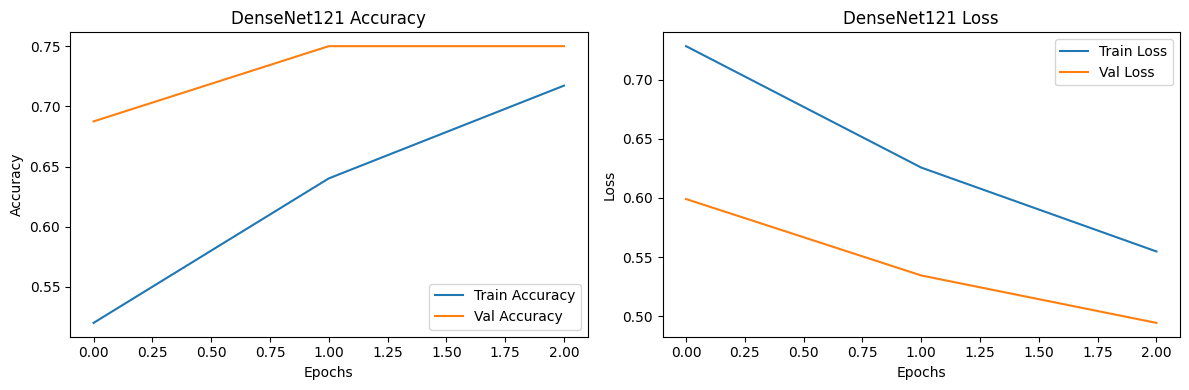

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 301ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step
=== Baseline CNN Classification Report ===
              precision    recall  f1-score   support

      Normal       0.89      0.83      0.86       234
   Pneumonia       0.90      0.94      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624

=== DenseNet121 Classification Report ===
              precision    recall  f1-score   support

      Normal       0.63      0.74      0.68       234
   Pneumonia       0.82      0.74      0.78       390

    accuracy                           0.74       624
   macro avg       0.72      0.74      0.73       624
weighted avg       0.75      0.74      0.74       624



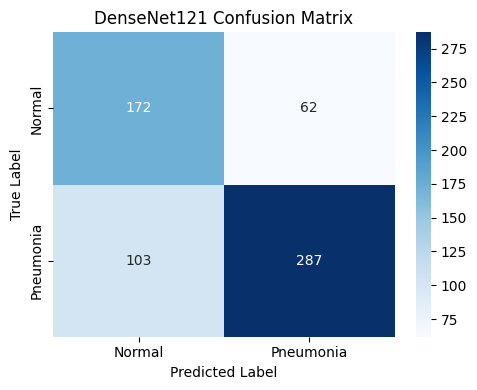

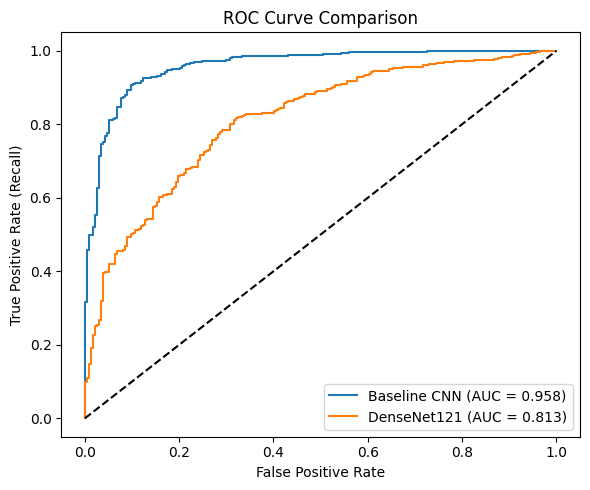

In [4]:
# 1. Training & Validation Accuracy/Loss Curves (DenseNet121)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_dense.history["accuracy"], label="Train Accuracy")
ax[0].plot(hist_dense.history["val_accuracy"], label="Val Accuracy")
ax[0].set_title("DenseNet121 Accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel("Accuracy")
ax[0].legend()

ax[1].plot(hist_dense.history["loss"], label="Train Loss")
ax[1].plot(hist_dense.history["val_loss"], label="Val Loss")
ax[1].set_title("DenseNet121 Loss")
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel("Loss")
ax[1].legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=300)
plt.show()

# 2. Evaluate on Test Set
y_true = np.concatenate([y for x, y in test_ds], axis=0).flatten()
y_probs_dense = densenet_model.predict(test_ds).flatten()
y_pred_dense = (y_probs_dense > 0.5).astype(int)

y_probs_cnn = cnn_model.predict(test_ds).flatten()
y_pred_cnn = (y_probs_cnn > 0.5).astype(int)

print("=== Baseline CNN Classification Report ===")
print(classification_report(y_true, y_pred_cnn, target_names=["Normal", "Pneumonia"]))

print("=== DenseNet121 Classification Report ===")
print(classification_report(y_true, y_pred_dense, target_names=["Normal", "Pneumonia"]))

# 3. Confusion Matrix
cm = confusion_matrix(y_true, y_pred_dense)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Pneumonia"], yticklabels=["Normal", "Pneumonia"])
plt.title("DenseNet121 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# 4. ROC Curve Comparison
fpr_cnn, tpr_cnn, _ = roc_curve(y_true, y_probs_cnn)
fpr_dense, tpr_dense, _ = roc_curve(y_true, y_probs_dense)

plt.figure(figsize=(6, 5))
plt.plot(fpr_cnn, tpr_cnn, label=f"Baseline CNN (AUC = {auc(fpr_cnn, tpr_cnn):.3f})")
plt.plot(fpr_dense, tpr_dense, label=f"DenseNet121 (AUC = {auc(fpr_dense, tpr_dense):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_17']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


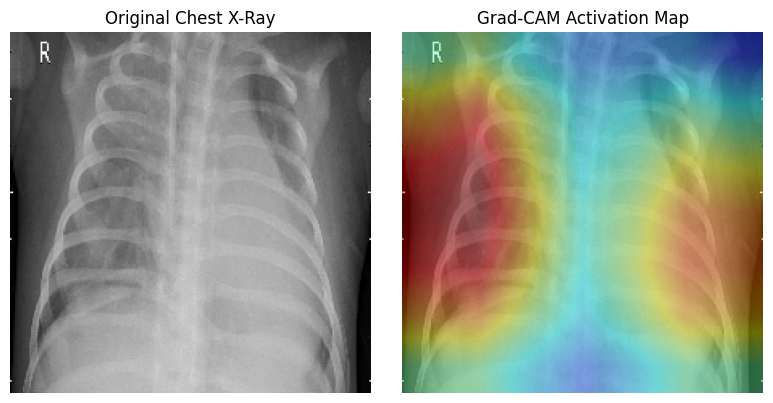

In [5]:
import cv2

def make_gradcam_heatmap(img_array, model, base_layer_name="densenet121", last_conv_layer_name="conv5_block16_concat"):
    base_model = model.get_layer(base_layer_name)
    grad_model = tf.keras.models.Model(
        [base_model.inputs], [base_model.get_layer(last_conv_layer_name).output, base_model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array / 255.0)
        loss = tf.reduce_mean(predictions)

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Pick one Pneumonia test image
sample_pneumonia_path = os.path.join(DATA_DIR, "test/PNEUMONIA", os.listdir(os.path.join(DATA_DIR, "test/PNEUMONIA"))[0])
img = tf.keras.utils.load_img(sample_pneumonia_path, target_size=(224, 224))
img_array = np.expand_dims(tf.keras.utils.img_to_array(img), axis=0)

heatmap = make_gradcam_heatmap(img_array, densenet_model)
heatmap_resized = cv2.resize(heatmap, (224, 224))
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(np.uint8(img_array[0]), 0.6, heatmap_colored, 0.4, 0)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(np.uint8(img_array[0]))
ax[0].set_title("Original Chest X-Ray")
ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
ax[1].set_title("Grad-CAM Activation Map")
ax[1].axis("off")
plt.tight_layout()
plt.savefig("gradcam_result.png", dpi=300)
plt.show()